# Softmax demo

Softmax turns a vector of raw scores (logits) into probabilities that are positive and sum to 1:

$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

We use a vector of length 3 and compute it three ways: pure Python, NumPy, and SciPy.

In [1]:
z = [2.0, -1.0, 0.1]
z

[2.0, -1.0, 0.1]

## 1. Pure Python (step by step)

In [2]:
import math

exps = [math.exp(x) for x in z]
total = sum(exps)
probs_py = [e / total for e in exps]

print('exp(z)  :', exps)
print('sum     :', total)
print('softmax :', probs_py)
print('sum of probabilities:', sum(probs_py))

exp(z)  : [7.38905609893065, 0.36787944117144233, 1.1051709180756477]
sum     : 8.86210645817774
softmax : [0.8337810128778362, 0.04151151229197568, 0.12470747483018807]
sum of probabilities: 1.0


### As a reusable function

In [6]:
def softmax_py(values):
    exps = [math.exp(v) for v in values]
    total = sum(exps)
    return [e / total for e in exps]

print('softmax :', softmax_py(z))
print('sum:     ', sum(softmax_py(z)))

softmax : [0.8337810128778362, 0.04151151229197568, 0.12470747483018807]
sum:      1.0


## 2. NumPy

In [4]:
import numpy as np

def softmax_np(values):
    values = np.asarray(values, dtype=float)
    exps = np.exp(values)
    return exps / exps.sum()

probs_np = softmax_np(z)
print(probs_np, probs_np.sum())

[0.83378101 0.04151151 0.12470747] 0.9999999999999999


## 3. SciPy (ready-made)

In [8]:
from scipy.special import softmax

probs_sp = softmax(z)
print(probs_sp, probs_sp.sum())

[0.83378101 0.04151151 0.12470747] 1.0000000000000002


## Compare the results

In [9]:
print('pure python:', np.round(probs_py, 4))
print('numpy      :', np.round(probs_np, 4))
print('scipy      :', np.round(probs_sp, 4))
print('all equal  :', np.allclose(probs_py, probs_np) and np.allclose(probs_np, probs_sp))

pure python: [0.8338 0.0415 0.1247]
numpy      : [0.8338 0.0415 0.1247]
scipy      : [0.8338 0.0415 0.1247]
all equal  : True


## Numerical stability

`exp` overflows for large inputs. Softmax is unchanged if we subtract the max from every element, so we do that first.

In [10]:
big = [1000.0, 1001.0, 1002.0]

def softmax_stable(values):
    values = np.asarray(values, dtype=float)
    exps = np.exp(values - values.max())
    return exps / exps.sum()

with np.errstate(over='ignore', invalid='ignore'):
    print('naive :', softmax_np(big))   # inf / inf -> nan
print('stable:', softmax_stable(big))
print('scipy :', softmax(big))

naive : [nan nan nan]
stable: [0.09003057 0.24472847 0.66524096]
scipy : [0.09003057 0.24472847 0.66524096]


## Visualize

Matplotlib is building the font cache; this may take a moment.


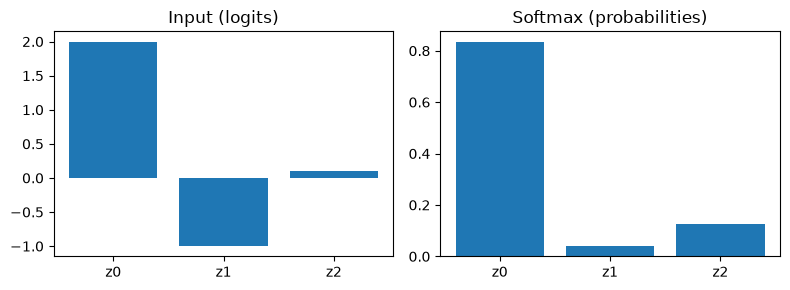

In [11]:
import matplotlib.pyplot as plt

labels = ['z0', 'z1', 'z2']
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar(labels, z)
axes[0].set_title('Input (logits)')
axes[1].bar(labels, softmax(z))
axes[1].set_title('Softmax (probabilities)')
plt.tight_layout()
plt.show()